# **Bayesian Optimization**

using Bo method to find the maximum thermal condutivity fr the SiOC ceramic composites based on the fraction of the phase

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
! pip install git+https://github.com/modAL-python/modAL.git

  Cloning https://github.com/modAL-python/modAL.git to /tmp/pip-req-build-z7fgphs_
  Running command git clone --filter=blob:none --quiet https://github.com/modAL-python/modAL.git /tmp/pip-req-build-z7fgphs_
  Resolved https://github.com/modAL-python/modAL.git to commit bba6f6fd00dbb862b1e09259b78caf6cffa2e755
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 kB 3.5 MB/s eta 0:00:00
  Created wheel for modAL-python: filename=modAL_python-0.4.2-py3-none-any.whl size=32650 sha256=aca85a32460b646a63048e19ebf5b55eb11c8320af43e59aca6d6fb6bdf61f14
  Stored in directory: /tmp/pip-ephem-wheel-cache-umuebnmb/wheels/d9/fb/59/7deb61b460c1c36394cd093758986ff7d36f71352dcb2e02c5
Successfully built modAL-python


In [3]:
##!pip install modAL

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import LinearLocator, FormatStrFormatter
from modAL.models import BayesianOptimizer
from sklearn.gaussian_process import GaussianProcessRegressor as GPR
from sklearn.gaussian_process.kernels import Matern, RBF, ExpSineSquared
from sklearn.svm import SVR
from modAL.acquisition import optimizer_EI, max_EI, max_UCB, PI
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split as tts
import os
from sklearn.gaussian_process import GaussianProcessRegressor
from modAL.models import BayesianOptimizer
from sklearn.svm import SVR
from sklearn.gaussian_process.kernels import Matern, RBF, ExpSineSquared

In [6]:
df=pd.read_csv("/content/drive/MyDrive/workshop/VolumeFraction.csv")

In [7]:
df.head(1)

,Unnamed: 0,File Names,Therm Cond.,SiO2,ß-SiC,seg-Carbon
0,0,M6LJOC.npy,2.46,0.05,0.004768,0.945232


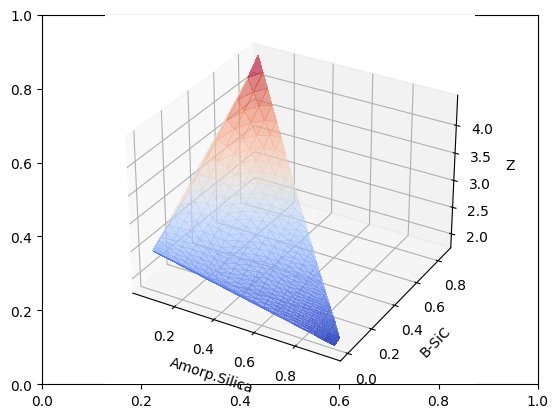

In [8]:

X = df['SiO2'].to_numpy()
Y = df['ß-SiC'].to_numpy()
Z = df['Therm Cond.'].to_numpy()

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
#ax = fig.gca(projection='3d')
ax=fig.add_subplot(projection = '3d')


surf = ax.plot_trisurf(X, Y, Z, cmap=cm.coolwarm,
                       linewidth=0, antialiased=False,alpha=0.6)

ax.set_xlabel("Amorp.Silica")
ax.set_ylabel("B-SiC")
ax.set_zlabel(r"Z")



plt.show()



In [9]:
X_s = np.vstack((X.flatten(), Y.flatten()))
X_s=X_s.T
print(np.shape(X_s))

SS_x = StandardScaler()
SS_y = StandardScaler()

X_t = SS_x.fit_transform(X_s)
y = Z.flatten()
y = SS_y.fit_transform(y.reshape(-1, 1))

print(np.shape(y))
X_initial, y_initial = X_t[90,:].reshape(1, -1), y[90].reshape(1, -1)

svr_lin = SVR(kernel="linear", C=100, gamma="auto")
svr_poly = SVR(kernel="poly", C=100, gamma="auto", degree=3, epsilon=0.1, coef0=1)
kernel = ExpSineSquared()
regressor = GaussianProcessRegressor(kernel=kernel,
                    alpha               = 5e-10,
                    copy_X_train        = False,
                    optimizer           = "fmin_l_bfgs_b",
                    n_restarts_optimizer= 50,
                    normalize_y         = False,
                    random_state        = None)



(360, 2)
(360, 1)


/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/_gpr.py:445: UserWarning: Predicted variances smaller than 0. Setting those variances to 0.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/_gpr.py:445: UserWarning: Predicted variances smaller than 0. Setting those variances to 0.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/modAL/acquisition.py:20: RuntimeWarning: divide by zero encountered in divide
  z = (mean - max_val - tradeoff) / std
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/_gpr.py:629: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.10/dist-packages/sklearn/gaussian_process/kernels.py:430: ConvergenceWarning: The optimal value found for dimension 0 of 

(2,)
Best points after n queries are: [[0.050002 0.859856]] [[4.48]]


/usr/local/lib/python3.10/dist-packages/mpl_toolkits/mplot3d/art3d.py:150: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  position3d = np.array((self._x, self._y, self._z))
/usr/local/lib/python3.10/dist-packages/mpl_toolkits/mplot3d/proj3d.py:210: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  return np.array([xs, ys, zs, np.ones_like(xs)])


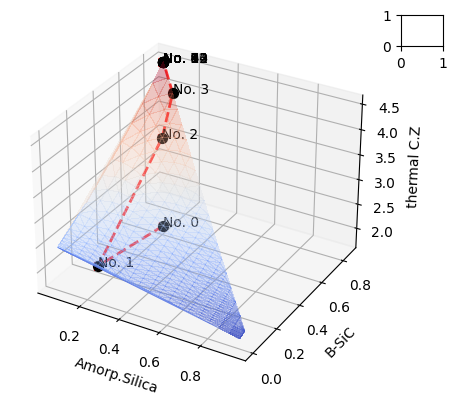

In [10]:

optimizer = BayesianOptimizer(estimator=regressor,
    X_training=X_initial,
    y_training=y_initial,
    query_strategy=max_EI)
query_list=[]
x_1=[]
x_2=[]
z_=[]
fig = plt.figure()
ax = fig.add_subplot(10, 10, 10)
#ax = fig.gca(projection='3d')
ax=fig.add_subplot(projection = '3d')

surf = ax.plot_trisurf(X.flatten(), Y.flatten(), Z.flatten(), cmap=cm.coolwarm,
                       linewidth=0, antialiased=False,alpha=0.3)
for n_query in range(15):
    query_idx, query_inst = optimizer.query(X_t)
    query_list.append(query_idx)
    optimizer.teach(X_t[query_idx,:].reshape(1, -1), y[query_idx].reshape(1, -1))

    y_pred, y_std = optimizer.predict(X_t, return_std=True)
    y_pred, y_std = y_pred.ravel(), y_std.ravel()
    X_max, y_max = optimizer.get_max()


    x1=SS_x.inverse_transform(X_t[query_idx,:].reshape(1, -1))[0][0]
    x2=SS_x.inverse_transform(X_t[query_idx,:].reshape(1, -1))[0][1]
    z=SS_y.inverse_transform(y[query_idx][0].reshape(-1, 1))
    x_1.append(x1)
    x_2.append(x2)
    z_.append(z[0][0])
    ax.scatter(x1,x2,z,  c='k', s=50)
    ax.text(x1, x2, z, "No. {:}  ".format(n_query), zdir=(0, 0, 0))
ax.set_xlabel("Amorp.Silica")
ax.set_ylabel("B-SiC")
ax.set_zlabel(r"thermal C.Z")
ax.plot(x_1, x_2, z_, 'r-->',alpha=0.8, linewidth=2)
X_max, y_max_in_queried = optimizer.get_max()
print(np.shape(X_max))
X_max_pred = SS_x.inverse_transform(X_max.reshape(1, -1))
y_max_data = SS_y.inverse_transform(y_max_in_queried.reshape(1, -1))
print("Best points after n queries are:", X_max_pred,y_max_data )


Looking at the first 10 measurement points it shows that the B-SiC phase is not affecting the traget, the thermal conductivity in any way. All of the best measurement points are along a very low B-SiC value. The Amorph Silica therefore is controlling the thermal conductivity: The less Amorph Silica there is in the system, the higher the thermal conductivity is. This explains the overall system. The system is controlled by the very high and very low correlation of the thermal conductivity with the given phase.